# 08. Wrap-up — 07 확정 결과에 대한 사후 분석

- **이 노트북은 07 확정 결과를 본 뒤의 사후 분석이다. 모델·설정·테스트 구간(D-03)은 변경하지 않는다.**
- 입력: `data/processed/master_features.parquet`, `data/processed/07_outputs/` (07 7-10 셀이 저장)
- 공통 정의: `src/common.py` (07 셀 정의와 동일, 아래 0절 assert로 재현 확인)
- 예정 산출물: 로지스틱 계수표 / 상위 5·10% 경보 지표 / #15 진단 / permutation importance(보조·사후) / results.csv·그림

## 0. 설정 + 07 결과 재현 확인

In [1]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from src.common import *

OUT = "data/processed/07_outputs"
meta = json.load(open(f"{OUT}/meta.json", encoding="utf-8"))
preds = {"stage1": pd.read_parquet(f"{OUT}/preds_stage1.parquet"),
         "stage2": pd.read_parquet(f"{OUT}/preds_stage2.parquet")}

master = load_master()
tr1, tr2, te1, te2 = build_frames(master)
grids = build_grids()
G = {"stage1": ("grid1_logit", "grid1_rf", tr1, te1, "late", NUM1),
     "stage2": ("grid2_logit", "grid2_rf", tr2, te2, "low",  NUM2)}

# 저장된 선택 설정으로 재적합 → 07 저장 예측값과 일치하는지 확인 (정의가 갈라지면 여기서 멈춤)
fitted = {}
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    assert (preds[stage]["order_id"].to_numpy() == te["order_id"].to_numpy()).all(), f"{stage}: 테스트 행 순서 불일치"
    for mdl, gname in [("logit", gl), ("rf", gr)]:
        sel = meta["models"][f"{stage}_{mdl}"]["selected"]
        pipe = fit_pipeline(get_maker(grids[gname], sel), tr, ycol, num, BIN1, CAT1)
        p = pipe.predict_proba(te[num + BIN1 + CAT1])[:, 1]
        diff = np.abs(p - preds[stage][f"prob_{mdl}"].to_numpy()).max()
        assert diff < 1e-6, f"{stage} {mdl}: 07 저장 예측과 최대 차이 {diff:.2e}"
        fitted[(stage, mdl)] = pipe
        print(f"OK {stage} {mdl} [{sel}]  PR-AUC {average_precision_score(preds[stage]['y'], p):.4f}  (max|Δp|={diff:.1e})")

OK stage1 logit [logit C=0.01]  PR-AUC 0.0523  (max|Δp|=0.0e+00)
OK stage1 rf [rf depth=4 leaf=50]  PR-AUC 0.0457  (max|Δp|=2.2e-16)
OK stage2 logit [logit C=0.01 cw=None]  PR-AUC 0.1353  (max|Δp|=0.0e+00)
OK stage2 rf [rf depth=8 leaf=50 cw=None]  PR-AUC 0.1350  (max|Δp|=1.1e-16)


## 1. 로지스틱 계수표 (방향)

- 07에서 선택된 설정으로 적합한 로지스틱의 계수 부호를 본다. **테스트 결과를 본 뒤의 보조·사후 확인**이며 모델·설정은 바꾸지 않는다.
- 선택된 C가 작아(강한 정규화) 계수 크기가 줄어 있다. 변수 간 크기 비교보다 **방향(부호)** 위주로 읽는다.
- 계수는 인과가 아니라 예측 기여 방향이다(계획서의 비인과 표현과 동일).

In [2]:
# 1. 로지스틱 계수표 — 07에서 선택된 설정(C=0.01 등)을 그대로 쓴 적합 모델의 방향 확인
def coef_table(stage, mdl="logit"):
    pipe = fitted[(stage, mdl)]
    names = pipe.named_steps["pre"].get_feature_names_out()
    coef = pipe.named_steps["clf"].coef_[0]
    t = pd.DataFrame({"type": [n.split("__", 1)[0] for n in names],
                      "feature": [n.split("__", 1)[1] for n in names], "coef": coef})
    t["odds_ratio"] = np.exp(t["coef"])
    t["방향"] = np.where(t["coef"] > 0, "↑ 위험 증가", "↓ 위험 감소")
    return t.reindex(t["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)

for stage, label in [("stage1", "1단계 late(지연)"), ("stage2", "2단계 low(저평점)")]:
    t = coef_table(stage)
    print(f"[{label}] {meta['models'][f'{stage}_logit']['selected']}")
    print("  num: 표준화 변수(1 표준편차 증가당) / bin: 0→1 / cat: 해당 범주 더미 (정규화 때문에 크기는 축소돼 있음 → 방향 위주로 해석)")
    print(t[t["type"] != "cat"].round(4).to_string(index=False))
    cat = t[t["type"] == "cat"]
    print(f"  category_grouped 더미 {len(cat)}개 중 |coef| 상위 5개")
    print(cat.head(5).round(4).to_string(index=False)); print()

[1단계 late(지연)] logit C=0.01
  num: 표준화 변수(1 표준편차 증가당) / bin: 0→1 / cat: 해당 범주 더미 (정규화 때문에 크기는 축소돼 있음 → 방향 위주로 해석)
type                      feature    coef  odds_ratio      방향
 num           distance_km_filled  0.3092      1.3623 ↑ 위험 증가
 num             seller_avg_delay  0.2583      1.2947 ↑ 위험 증가
 bin seller_avg_delay_is_fallback -0.0643      0.9378 ↓ 위험 감소
 bin                 dist_missing  0.0434      1.0444 ↑ 위험 증가
  category_grouped 더미 24개 중 |coef| 상위 5개
type                              feature    coef  odds_ratio      방향
 cat category_grouped_luggage_accessories -0.2448      0.7828 ↓ 위험 감소
 cat                category_grouped_baby  0.2186      1.2444 ↑ 위험 증가
 cat     category_grouped_home_appliances -0.2026      0.8166 ↓ 위험 감소
 cat         category_grouped_electronics  0.2004      1.2219 ↑ 위험 증가
 cat      category_grouped_bed_bath_table  0.1929      1.2127 ↑ 위험 증가

[2단계 low(저평점)] logit C=0.01 cw=None
  num: 표준화 변수(1 표준편차 증가당) / bin: 0→1 / cat: 해당 범주 더미 (정규화 때문에 크기는 축소돼 있음 → 방향 

## 2. 상위 5%·10% 경보 지표 (사후)

- 테스트 구간에서 예측확률 상위 5%·10%를 경보로 가정했을 때 precision, lift(= precision / 기저율), captured(= 전체 양성 중 잡힌 비율).
- 정렬 방식이 07의 `lift_top`과 같아서, 10% lift가 07 결과(`cv_results.csv`의 `lift_top10`)와 일치하는지 assert로 확인한다.
- 양성 수가 적은 1단계(late)는 경보 건수가 작아 숫자가 흔들릴 수 있다.

In [3]:
# 2. 상위 5%·10% 경보 지표 — 테스트 구간, 1·2단계 × 로지스틱·RF
cv07 = pd.read_csv(f"{OUT}/cv_results.csv")
ORDER = [("stage1", "logit"), ("stage1", "rf"), ("stage2", "logit"), ("stage2", "rf")]   # cv_results 순서와 동일
FRACS = [0.05, 0.10]

def alert_metrics(y, p, frac):
    k = max(int(len(y) * frac), 1); idx = np.argsort(-p)[:k]     # 07 lift_top 과 같은 정렬
    tp = int(y[idx].sum()); prec = tp / k
    return {"n_alert": k, "TP": tp, "precision": prec, "lift": prec / y.mean(), "captured": tp / y.sum()}

rows = []
for i, (stage, mdl) in enumerate(ORDER):
    y = preds[stage]["y"].to_numpy(); p = preds[stage][f"prob_{mdl}"].to_numpy()
    sel = meta["models"][f"{stage}_{mdl}"]["selected"]
    assert sel in cv07.loc[i, "name"], (sel, cv07.loc[i, "name"])
    for f in FRACS:
        r = alert_metrics(y, p, f)
        if f == 0.10:   # 07 7-3/7-5 의 lift_top10 과 일치해야 함
            assert np.isclose(r["lift"], cv07.loc[i, "lift_top10"]), (stage, mdl, r["lift"], cv07.loc[i, "lift_top10"])
        rows.append({"단계": stage, "모델": sel, "상위%": int(f * 100), "기저율": y.mean(), **r})
alert_df = pd.DataFrame(rows)
print("기저율 = 무작위로 뽑았을 때의 precision (lift 1.0). captured = 전체 양성 중 경보에 잡힌 비율")
print(alert_df.round(4).to_string(index=False))

기저율 = 무작위로 뽑았을 때의 precision (lift 1.0). captured = 전체 양성 중 경보에 잡힌 비율
    단계                         모델  상위%   기저율  n_alert  TP  precision   lift  captured
stage1               logit C=0.01    5 0.044     1267 103     0.0813 1.8484    0.0924
stage1               logit C=0.01   10 0.044     2535 161     0.0635 1.4441    0.1444
stage1         rf depth=4 leaf=50    5 0.044     1267  65     0.0513 1.1665    0.0583
stage1         rf depth=4 leaf=50   10 0.044     2535 148     0.0584 1.3275    0.1327
stage2       logit C=0.01 cw=None    5 0.100     1262 224     0.1775 1.7744    0.0887
stage2       logit C=0.01 cw=None   10 0.100     2524 401     0.1589 1.5882    0.1588
stage2 rf depth=8 leaf=50 cw=None    5 0.100     1262 217     0.1719 1.7189    0.0859
stage2 rf depth=8 leaf=50 cw=None   10 0.100     2524 403     0.1597 1.5962    0.1596


## 3. #15 진단: 성능이 기저율 수준일 때 (사후)

실행계획서 6절 #15의 5개 절차를 07 확정 결과에 대해 수행한다. **테스트 결과를 본 뒤의 사후 진단이며 모델·설정·테스트 구간은 변경하지 않는다.** 목적은 "버그라서 낮은 것"과 "정보 부족이라 낮은 것"을 구분하는 것이다.

| 계획서 절차 | 이 노트북 |
|---|---|
| 1. 무작위 라벨 테스트 | 3-1 |
| 2. 학습 vs 검증 격차 | 3-3 (학습 in-sample vs 테스트) |
| 3. 단순 모델과 비교 | 3-4 |
| 4. 랜덤 10건 눈 대조 | 3-5 |
| 5. 단변량(거리 사분위) | 3-6 |
| (기록) 더미 accuracy | 3-0 |
| (추가) 양성 대조 | 3-2 — 계획서 5개 항목 밖의 추가 점검 |

### 3-0. 더미 accuracy

In [4]:
# 3-0. 더미 모델 accuracy (accuracy 착시 기록) + 3절 결과 모음 dict
from sklearn.dummy import DummyClassifier
diag = {}   # 3절 결과 (results.csv 로 모을 때 사용)

def ratio(y, p):
    return average_precision_score(y, p) / y.mean()

for stage, (gl, gr, tr, te, ycol, num) in G.items():
    d = DummyClassifier(strategy="most_frequent").fit(tr[num], tr[ycol].astype(int))
    y_te = te[ycol].astype(int)
    acc = float((d.predict(te[num]) == y_te).mean())
    diag[f"{stage}_dummy_acc"] = acc
    print(f"[{stage}] 항상 '정상'만 찍는 더미 accuracy {acc:.3f}  (양성 기저율 {y_te.mean():.3f}) → accuracy는 착시, PR-AUC·lift 사용")

[stage1] 항상 '정상'만 찍는 더미 accuracy 0.956  (양성 기저율 0.044) → accuracy는 착시, PR-AUC·lift 사용
[stage2] 항상 '정상'만 찍는 더미 accuracy 0.900  (양성 기저율 0.100) → accuracy는 착시, PR-AUC·lift 사용


### 3-1. 무작위 라벨 테스트
학습 라벨만 섞고 테스트는 실제 라벨로 평가한다. 섞은 결과가 1.0 근처면 파이프라인은 정직하게 랜덤으로 동작한다.

In [5]:
# 3-1. 무작위 라벨 테스트: 학습 라벨만 섞어서 같은 파이프라인 → 테스트 PR-AUC/기저율이 1.0 근처여야 정상
N_SHUF = 5
rows = []
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    y_te = te[ycol].astype(int).to_numpy()
    for mdl, gname in [("logit", gl), ("rf", gr)]:
        sel = meta["models"][f"{stage}_{mdl}"]["selected"]; mk = get_maker(grids[gname], sel)
        rs = []
        for s in range(N_SHUF):
            trs = tr.copy(); trs[ycol] = np.random.default_rng(s).permutation(tr[ycol].to_numpy())
            rs.append(ratio(y_te, fit_prob(mk, trs, ycol, num, BIN1, CAT1, te)))
        real = ratio(y_te, preds[stage][f"prob_{mdl}"].to_numpy())
        rows.append({"단계": stage, "모델": sel, "실제 라벨": real, "섞은 라벨 평균": np.mean(rs),
                     "섞은 라벨 최소": np.min(rs), "섞은 라벨 최대": np.max(rs)})
shuf_df = pd.DataFrame(rows); diag["label_shuffle"] = shuf_df
print(f"PR-AUC / 기저율 (섞기 {N_SHUF}회, 시드 0~{N_SHUF-1})")
print(shuf_df.round(3).to_string(index=False))

PR-AUC / 기저율 (섞기 5회, 시드 0~4)
    단계                         모델  실제 라벨  섞은 라벨 평균  섞은 라벨 최소  섞은 라벨 최대
stage1               logit C=0.01  1.189     1.002     0.889     1.170
stage1         rf depth=4 leaf=50  1.038     0.963     0.878     1.038
stage2       logit C=0.01 cw=None  1.352     1.056     0.986     1.129
stage2 rf depth=8 leaf=50 cw=None  1.349     1.063     1.004     1.114


### 3-2. 양성 대조 (추가 점검)
신호가 있을 때 파이프라인이 잡아내는지 확인한다. 라벨 정보를 일부러 넣은 변수는 평가용 장치일 뿐 모델 변수가 아니다.

In [6]:
# 3-2. 양성 대조(추가 점검, 실행계획서 #15 5개 항목 밖): 라벨 + 잡음 변수를 일부러 넣었을 때 파이프라인이 신호를 잡는지
rows = []
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    sel = meta["models"][f"{stage}_logit"]["selected"]; mk = get_maker(grids[gl], sel)
    trp, tep = tr.copy(), te.copy(); rng = np.random.default_rng(0)
    for d in (trp, tep):
        d["_pos"] = d[ycol].astype(int).to_numpy() + rng.normal(0, 1, len(d))
    p = fit_prob(mk, trp, ycol, num + ["_pos"], BIN1, CAT1, tep)
    rows.append({"단계": stage, "모델": sel, "양성 대조 PR-AUC/기저율": ratio(tep[ycol].astype(int).to_numpy(), p)})
pos_df = pd.DataFrame(rows); diag["positive_control"] = pos_df
print("의도적으로 라벨 정보를 넣은 변수가 있으면 비율이 크게 올라야 정상 (파이프라인이 신호를 못 잡는 버그가 아니라는 증거)")
print(pos_df.round(3).to_string(index=False))

의도적으로 라벨 정보를 넣은 변수가 있으면 비율이 크게 올라야 정상 (파이프라인이 신호를 못 잡는 버그가 아니라는 증거)
    단계                   모델  양성 대조 PR-AUC/기저율
stage1         logit C=0.01             2.927
stage2 logit C=0.01 cw=None             3.033


### 3-3. 학습 vs 테스트 격차
학습 in-sample에서만 높으면 과적합 신호다. (07의 CV 점수가 아니라 학습 전체 in-sample 값이다.)

In [7]:
# 3-3. 학습 vs 테스트 격차: 학습(in-sample)에서만 높으면 과적합
rows = []
for (stage, mdl), pipe in fitted.items():
    gl, gr, tr, te, ycol, num = G[stage]
    ytr = tr[ycol].astype(int).to_numpy()
    ptr = pipe.predict_proba(tr[num + BIN1 + CAT1])[:, 1]
    rows.append({"단계": stage, "모델": meta["models"][f"{stage}_{mdl}"]["selected"],
                 "학습(in-sample)": ratio(ytr, ptr), "테스트": ratio(preds[stage]["y"].to_numpy(), preds[stage][f"prob_{mdl}"].to_numpy())})
gap_df = pd.DataFrame(rows); gap_df["격차"] = gap_df["학습(in-sample)"] - gap_df["테스트"]; diag["train_test_gap"] = gap_df
print("PR-AUC / 기저율")
print(gap_df.round(3).to_string(index=False))

PR-AUC / 기저율
    단계                         모델  학습(in-sample)   테스트    격차
stage1               logit C=0.01          1.535 1.189 0.346
stage1         rf depth=4 leaf=50          1.875 1.038 0.837
stage2       logit C=0.01 cw=None          1.416 1.352 0.063
stage2 rf depth=8 leaf=50 cw=None          1.741 1.349 0.392


### 3-4. 단순 모델과 비교
로지스틱도 안 오르면 정보 부족, RF만 못 오르면 튜닝 문제다.

In [8]:
# 3-4. 단순 모델과 비교: 로지스틱·RF·거리 하나만 쓴 점수 (테스트 PR-AUC/기저율)
rows = []
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    y_te = te[ycol].astype(int).to_numpy()
    rows.append({"단계": stage,
                 "거리 단독(+)": ratio(y_te, te["distance_km_filled"].to_numpy()),
                 "로지스틱": ratio(y_te, preds[stage]["prob_logit"].to_numpy()),
                 "RF": ratio(y_te, preds[stage]["prob_rf"].to_numpy())})
cmp_df = pd.DataFrame(rows); diag["model_compare"] = cmp_df
print(cmp_df.round(3).to_string(index=False))

    단계  거리 단독(+)  로지스틱    RF
stage1     1.054 1.189 1.038
stage2     1.064 1.352 1.349


### 3-5. 랜덤 10건 눈 대조
master의 거리·셀러·카테고리가 원본과 맞게 붙었는지 직접 대조한다. (표 두 개를 눈으로 비교하고 결과를 아래 셀에 적는다.)

In [9]:
# 3-5. 랜덤 10건 눈 대조: master 의 피처 vs 원본 CSV (대표 아이템 기준: 셀러·거리=가장 먼 아이템, 카테고리=가격 최대 아이템)
sample = te1.sample(10, random_state=42)
show = [c for c in ["order_id", "purchase_ts", "order_estimated_delivery_date", "order_delivered_customer_date",
                    "late", "low", "distance_km_filled", "dist_missing", "seller_avg_delay", "category_grouped"] if c in te1.columns]
print("[master 쪽]"); print(sample[show].to_string(index=False))

RAW = "data/raw"
try:
    items = pd.read_csv(f"{RAW}/olist_order_items_dataset.csv")
    prods = pd.read_csv(f"{RAW}/olist_products_dataset.csv")[["product_id", "product_category_name"]]
    sellers = pd.read_csv(f"{RAW}/olist_sellers_dataset.csv")
    orders = pd.read_csv(f"{RAW}/olist_orders_dataset.csv")[["order_id", "customer_id"]]
    cust = pd.read_csv(f"{RAW}/olist_customers_dataset.csv")[["customer_id", "customer_zip_code_prefix", "customer_state"]]
    raw = (items[items["order_id"].isin(sample["order_id"])]
           .merge(prods, on="product_id", how="left").merge(sellers, on="seller_id", how="left")
           .merge(orders, on="order_id").merge(cust, on="customer_id"))
    print("\n[원본 쪽] 아이템 단위 (멀티 아이템 주문은 여러 줄)")
    print(raw[["order_id", "order_item_id", "seller_id", "seller_zip_code_prefix", "seller_state",
               "customer_zip_code_prefix", "customer_state", "product_category_name", "price"]]
          .sort_values(["order_id", "order_item_id"]).to_string(index=False))
except FileNotFoundError as e:
    print("\n원본 CSV 경로를 확인해줘 (RAW 변수):", e)

[master 쪽]
                        order_id         purchase_ts order_estimated_delivery_date order_delivered_customer_date  late  low  distance_km_filled  dist_missing  seller_avg_delay      category_grouped
48c923725afb1e9fc4d686c4ffb3cf03 2018-08-21 17:00:16                    2018-09-10           2018-08-27 14:32:30     0  0.0          512.708322             0          0.067486         health_beauty
a61e700a88111a17f8158f275c06631d 2018-06-20 18:12:20                    2018-07-20           2018-06-27 00:14:32     0  1.0          348.231577             0          0.233129 computers_accessories
8d8f38e4ae1cf25848c0570ff236958b 2018-07-20 11:26:01                    2018-08-13           2018-07-31 16:44:28     0  0.0          310.486908             0          0.052345         watches_gifts
611aef870c45d1ba9c852bab44e25f36 2018-06-11 18:19:19                    2018-07-12           2018-06-26 22:12:13     0  0.0          499.358904             0          0.102041                    기타

**3-5 대조 결과 (Day 6 후속)**: 10건 모두 master와 원본이 일치했다.
- 카테고리: 포르투갈어 → 영문 매핑 10/10 일치. `기타`로 묶인 2건(`casa_construcao`, `livros_tecnicos`)은 주문 단위 대표 카테고리 기준 27위(472건)·34위(254건)로 D-02 상위 22개 밖이다.
- 라벨: 원본 orders의 날짜 비교로 다시 계산한 late와, D-00b 규칙(최신 응답 1건)으로 고른 리뷰의 low가 master와 10/10 일치했다(late=1은 1건뿐). 이 재계산은 노트북 밖에서 했다.
- 거리: geolocation으로 다시 계산하지 않았다. 셀러·고객 우편번호가 가리키는 주·도시 위치로 어림했을 때 이상한 값은 없었다(정밀 검증 아님).
- 한계: 10건이라 드문 오류는 못 잡는다. "오류 없음"이 아니라 "오류 징후 없음"으로 기록한다.

### 3-6. 거리 사분위별 지연율 (단변량)

In [10]:
# 3-6. 단변량 확인: 거리 사분위별 지연율/저평점률 (사분위 경계는 학습 구간 기준, 거리 결측(대체값) 행 제외)
ok = tr1.loc[tr1["dist_missing"] == 0, "distance_km_filled"]
edges = ok.quantile([0, .25, .5, .75, 1]).to_numpy(copy=True); edges[0], edges[-1] = -np.inf, np.inf
labels = ["Q1(가까움)", "Q2", "Q3", "Q4(멈)"]
for name, d, ycol in [("학습", tr1, "late"), ("테스트", te1, "late"), ("학습", tr2, "low"), ("테스트", te2, "low")]:
    dd = d[d["dist_missing"] == 0].copy()
    dd["거리구간"] = pd.cut(dd["distance_km_filled"], edges, labels=labels)
    g = dd.groupby("거리구간", observed=True)[ycol].agg(n="size", 비율="mean").round(4)
    g["기저율 대비"] = (g["비율"] / dd[ycol].astype(int).mean()).round(2)
    print(f"[{name} · {ycol}] 전체 기저율 {dd[ycol].astype(int).mean():.4f}"); print(g.to_string()); print()

[학습 · late] 전체 기저율 0.0764
             n      비율  기저율 대비
거리구간                          
Q1(가까움)  17622  0.0411    0.54
Q2       17622  0.0758    0.99
Q3       17621  0.0845    1.11
Q4(멈)    17622  0.1041    1.36

[테스트 · late] 전체 기저율 0.0437
            n      비율  기저율 대비
거리구간                         
Q1(가까움)  7669  0.0580    1.33
Q2       6129  0.0315    0.72
Q3       5707  0.0321    0.73
Q4(멈)    5735  0.0493    1.13

[학습 · low] 전체 기저율 0.1381
             n      비율  기저율 대비
거리구간                          
Q1(가까움)  17505  0.1038    0.75
Q2       17480  0.1430    1.04
Q3       17480  0.1460    1.06
Q4(멈)    17490  0.1597    1.16

[테스트 · low] 전체 기저율 0.0999
            n      비율  기저율 대비
거리구간                         
Q1(가까움)  7632  0.0921    0.92
Q2       6111  0.0982    0.98
Q3       5680  0.1028    1.03
Q4(멈)    5707  0.1093    1.09



### 3절 해석 (사후)
- 파이프라인 오류 징후는 없다: 눈 대조 10건 일치(3-5), 양성 대조 2.9~3.0배(3-2), 라벨 섞기 평균 0.96~1.06배(3-1).
- 2단계는 약하지만 노이즈 위다: 실제 1.35배, 섞은 라벨 최대 1.13배(3-1). 개선의 대부분은 `freight_sum` 단독으로 재현된다(07 7-7. 3-4의 2단계 "거리 단독" 열은 freight_sum이 아니라 거리 단독 기준선).
- 1단계는 5회 기준으로 섞은 라벨 범위 안이다(로지스틱 1.189 vs 최대 1.170, RF 1.038 vs 최대 1.038). 학습 구간의 거리 효과(Q1 0.54배 → Q4 1.36배)가 테스트에서 재현되지 않는 것(3-6)은 07 6절의 2018-08 distance 관계 역전과 같은 방향이다.
- 학습 vs 테스트 격차(3-3)는 학습 기저율 7.6%와 테스트 4.4%의 차이가 섞여 있어 과적합만의 효과로 해석하지 않는다.
- 한계: 섞기가 5회뿐이고, 1단계 로지스틱은 부트스트랩 구간으로는 구분되지만 섞기로는 구분이 어렵다(D-21 한계 ①, D-22).

## 4. permutation importance (보조·사후)

- **학습 구간의 마지막 CV 검증 fold 기준**이다(07 7절과 같은 `TimeSeriesSplit` + gap 분할의 마지막 fold). 테스트 구간은 쓰지 않는다.
- 보조·사후 지표이며 **결론에는 쓰지 않는다**(계획서 질문 2 "1·2단계 변수 중요도가 겹치는가"의 답과 분리). 해석은 "예측 기여도"이고 인과가 아니다.
- 마지막 fold 하나라서 순위가 흔들릴 수 있다. 하락폭이 반복 표준편차 이내인 변수끼리의 순위는 의미가 없다.
- 방향은 1절 로지스틱 계수표로 본다.

### 4-1. permutation importance (마지막 검증 fold)

In [11]:
# 4-1. permutation importance — 학습 구간의 마지막 CV 검증 fold 기준 (테스트 구간은 쓰지 않음)
from sklearn.inspection import permutation_importance
N_REP = 10
rows, info = [], []
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    a, b = make_splits(len(tr))[-1]                      # 07 7절과 같은 분할(TimeSeriesSplit, gap)의 마지막 fold
    fa, fb = tr.iloc[a], tr.iloc[b]
    cols = num + BIN1 + CAT1; yb = fb[ycol].astype(int).to_numpy()
    info.append(f"[{stage}] 마지막 fold: 학습 {len(fa):,}건 / 검증 {len(fb):,}건, 검증 양성 {int(yb.sum()):,}건 (기저율 {yb.mean():.4f})")
    for mdl, gname in [("logit", gl), ("rf", gr)]:
        sel = meta["models"][f"{stage}_{mdl}"]["selected"]
        pipe = fit_pipeline(get_maker(grids[gname], sel), fa, ycol, num, BIN1, CAT1)
        base_ap = average_precision_score(yb, pipe.predict_proba(fb[cols])[:, 1])
        r = permutation_importance(pipe, fb[cols], yb, scoring="average_precision",
                                   n_repeats=N_REP, random_state=42, n_jobs=1)
        for j, c in enumerate(cols):
            rows.append({"단계": stage, "모델": mdl, "변수": c, "기준 PR-AUC/기저율": base_ap / yb.mean(),
                         "하락(PR-AUC/기저율)": r.importances_mean[j] / yb.mean(), "표준편차": r.importances_std[j] / yb.mean()})
print("\n".join(info))
perm_df = pd.DataFrame(rows); diag["perm_importance"] = perm_df
for (stage, mdl), g in perm_df.groupby(["단계", "모델"], sort=False):
    print(f"\n[{stage} · {mdl}] 변수를 섞었을 때 PR-AUC/기저율 하락폭 (클수록 기여, 0 이하면 기여 없음, {N_REP}회 평균)")
    print(g.sort_values("하락(PR-AUC/기저율)", ascending=False)[["변수", "기준 PR-AUC/기저율", "하락(PR-AUC/기저율)", "표준편차"]].round(4).to_string(index=False))

[stage1] 마지막 fold: 학습 54,044건 / 검증 11,808건, 검증 양성 1,104건 (기저율 0.0935)
[stage2] 마지막 fold: 학습 53,600건 / 검증 11,719건, 검증 양성 1,748건 (기저율 0.1492)

[stage1 · logit] 변수를 섞었을 때 PR-AUC/기저율 하락폭 (클수록 기여, 0 이하면 기여 없음, 10회 평균)
                          변수  기준 PR-AUC/기저율  하락(PR-AUC/기저율)   표준편차
          distance_km_filled         1.3665          0.3938 0.0143
                dist_missing         1.3665         -0.0001 0.0005
seller_avg_delay_is_fallback         1.3665         -0.0005 0.0002
            category_grouped         1.3665         -0.0099 0.0135
            seller_avg_delay         1.3665         -0.0524 0.0304

[stage1 · rf] 변수를 섞었을 때 PR-AUC/기저율 하락폭 (클수록 기여, 0 이하면 기여 없음, 10회 평균)
                          변수  기준 PR-AUC/기저율  하락(PR-AUC/기저율)   표준편차
          distance_km_filled         1.6473          0.5991 0.0244
            seller_avg_delay         1.6473          0.0521 0.0320
            category_grouped         1.6473          0.0469 0.0424
seller_avg_delay_is_fallback         1.6473    

### 4-2. 1·2단계 대조표 (공통 변수)

In [12]:
# 4-2. 1·2단계 대조표: 두 단계에 공통인 변수만, 단계 안에서의 순위 (1 = 하락폭 최대)
common = NUM1 + BIN1 + CAT1
rank_rows = []
for mdl in ["logit", "rf"]:
    t = {}
    for stage in ["stage1", "stage2"]:
        g = perm_df[(perm_df["단계"] == stage) & (perm_df["모델"] == mdl) & (perm_df["변수"].isin(common))].set_index("변수")
        t[f"{stage} 하락"] = g["하락(PR-AUC/기저율)"]
        t[f"{stage} 순위"] = g["하락(PR-AUC/기저율)"].rank(ascending=False).astype(int)
        t[f"{stage} 노이즈초과"] = np.where(g["하락(PR-AUC/기저율)"] > np.maximum(2 * g["표준편차"], 0.01), "○", "–")
    d = pd.DataFrame(t).reset_index().rename(columns={"index": "변수"}); d.insert(0, "모델", mdl); rank_rows.append(d)
rank_df = pd.concat(rank_rows).sort_values(["모델", "stage1 순위"]); diag["perm_rank_compare"] = rank_df
print("보조·사후 지표. 마지막 fold 한 개 기준이라 순위가 흔들릴 수 있으며 결론에는 쓰지 않는다(계획서 질문 2의 답과 분리).")
print("노이즈초과 ○ = 하락폭이 표준편차의 2배보다 크고 0.01 이상. – 인 변수끼리의 순위는 의미 없음.")
print(rank_df.round(4).to_string(index=False))

보조·사후 지표. 마지막 fold 한 개 기준이라 순위가 흔들릴 수 있으며 결론에는 쓰지 않는다(계획서 질문 2의 답과 분리).
노이즈초과 ○ = 하락폭이 표준편차의 2배보다 크고 0.01 이상. – 인 변수끼리의 순위는 의미 없음.
   모델                           변수  stage1 하락  stage1 순위 stage1 노이즈초과  stage2 하락  stage2 순위 stage2 노이즈초과
logit           distance_km_filled     0.3938          1            ○     0.0539          1            ○
logit                 dist_missing    -0.0001          2            –     0.0004          4            –
logit seller_avg_delay_is_fallback    -0.0005          3            –    -0.0027          5            –
logit             category_grouped    -0.0099          4            –     0.0396          2            ○
logit             seller_avg_delay    -0.0524          5            –     0.0159          3            –
   rf           distance_km_filled     0.5991          1            ○     0.0603          1            ○
   rf             seller_avg_delay     0.0521          2            –     0.0290          3            –
   rf             category_gr

## 5. 결과 정리: 표 저장 + 그림 (사후)

- `outputs/tables/`: `results.csv`(단계×모델 한 줄), `results_monthly.csv`(월별 PR-AUC/기저율), `perm_importance_last_fold.csv`(보조·사후)
- `outputs/figures/`: `08_monthly_ratio.png`, `08_pr_curves.png`, `08_perm_importance.png`
- 07 확정 결과 + 08 사후 분석을 한 표로 모은 것이다. 월별 값은 07이 저장한 테스트 예측값으로 08에서 다시 계산했다(모델·설정 변경 없음).

### 5-1. 결과 표 저장

In [13]:
# 5-1. 결과 표 저장 (outputs/tables) — results.csv / results_monthly.csv / perm_importance_last_fold.csv
import os
FIG_DIR, TAB_DIR = "outputs/figures", "outputs/tables"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

# (a) results.csv: 단계 × 모델 한 줄 (07 테스트 결과 + 08 사후 지표)
rows = []
for stage, mdl in ORDER:
    m_ = meta["models"][f"{stage}_{mdl}"]; sel = m_["selected"]
    y = preds[stage]["y"].to_numpy()
    row = {"단계": stage, "모델": mdl, "선택 설정": sel, "n_test": len(y), "양성 기저율": y.mean(),
           "PR-AUC": m_["pr_auc"], "PR-AUC/기저율": m_["pr_auc"] / y.mean(), "F1 임계값": m_["thr"]}
    for f in (5, 10):
        a = alert_df[(alert_df["단계"] == stage) & (alert_df["모델"] == sel) & (alert_df["상위%"] == f)].iloc[0]
        row.update({f"top{f}_precision": a["precision"], f"top{f}_lift": a["lift"], f"top{f}_captured": a["captured"]})
    sh = diag["label_shuffle"]; sh = sh[(sh["단계"] == stage) & (sh["모델"] == sel)].iloc[0]
    gp = diag["train_test_gap"]; gp = gp[(gp["단계"] == stage) & (gp["모델"] == sel)].iloc[0]
    row.update({"섞은라벨_평균비율": sh["섞은 라벨 평균"], "학습_in-sample_비율": gp["학습(in-sample)"],
                "더미_accuracy": diag[f"{stage}_dummy_acc"]})
    rows.append(row)
results = pd.DataFrame(rows)
results.to_csv(f"{TAB_DIR}/results.csv", index=False, encoding="utf-8-sig")

# (b) 월별 PR-AUC/기저율 (저장된 테스트 예측값으로 08에서 재계산)
mrows = []
for stage, (gl, gr, tr, te, ycol, num) in G.items():
    month = te["purchase_ts"].dt.to_period("M").astype(str).to_numpy()
    for mdl in ["logit", "rf"]:
        p_all = preds[stage][f"prob_{mdl}"].to_numpy(); y_all = preds[stage]["y"].to_numpy()
        for mo in sorted(set(month)):
            k = month == mo; y, p = y_all[k], p_all[k]
            ok = y.sum() > 0
            mrows.append({"단계": stage, "모델": mdl, "월": mo, "n": int(k.sum()), "양성": int(y.sum()), "기저율": y.mean(),
                          "PR-AUC": average_precision_score(y, p) if ok else np.nan,
                          "PR-AUC/기저율": average_precision_score(y, p) / y.mean() if ok else np.nan})
monthly = pd.DataFrame(mrows)
monthly.to_csv(f"{TAB_DIR}/results_monthly.csv", index=False, encoding="utf-8-sig")

# (c) permutation importance (보조·사후, 마지막 검증 fold)
perm_df.to_csv(f"{TAB_DIR}/perm_importance_last_fold.csv", index=False, encoding="utf-8-sig")

print("저장:", sorted(os.listdir(TAB_DIR)))
print("\n[results.csv]"); print(results.round(4).T.to_string(header=False))
print("\n[월별 PR-AUC/기저율]"); print(monthly.pivot_table(index=["단계", "모델"], columns="월", values="PR-AUC/기저율").round(3).to_string())

저장: ['perm_importance_last_fold.csv', 'results.csv', 'results_monthly.csv']

[results.csv]
단계                     stage1              stage1                stage2                      stage2
모델                      logit                  rf                 logit                          rf
선택 설정            logit C=0.01  rf depth=4 leaf=50  logit C=0.01 cw=None  rf depth=8 leaf=50 cw=None
n_test                  25352               25352                 25242                       25242
양성 기저율                  0.044               0.044                   0.1                         0.1
PR-AUC                 0.0523              0.0457                0.1353                       0.135
PR-AUC/기저율             1.1892              1.0385                1.3521                      1.3494
F1 임계값                 0.5188              0.5135                0.1108                       0.114
top5_precision         0.0813              0.0513                0.1775                      0.1719
top5_lift

### 5-2. 그림

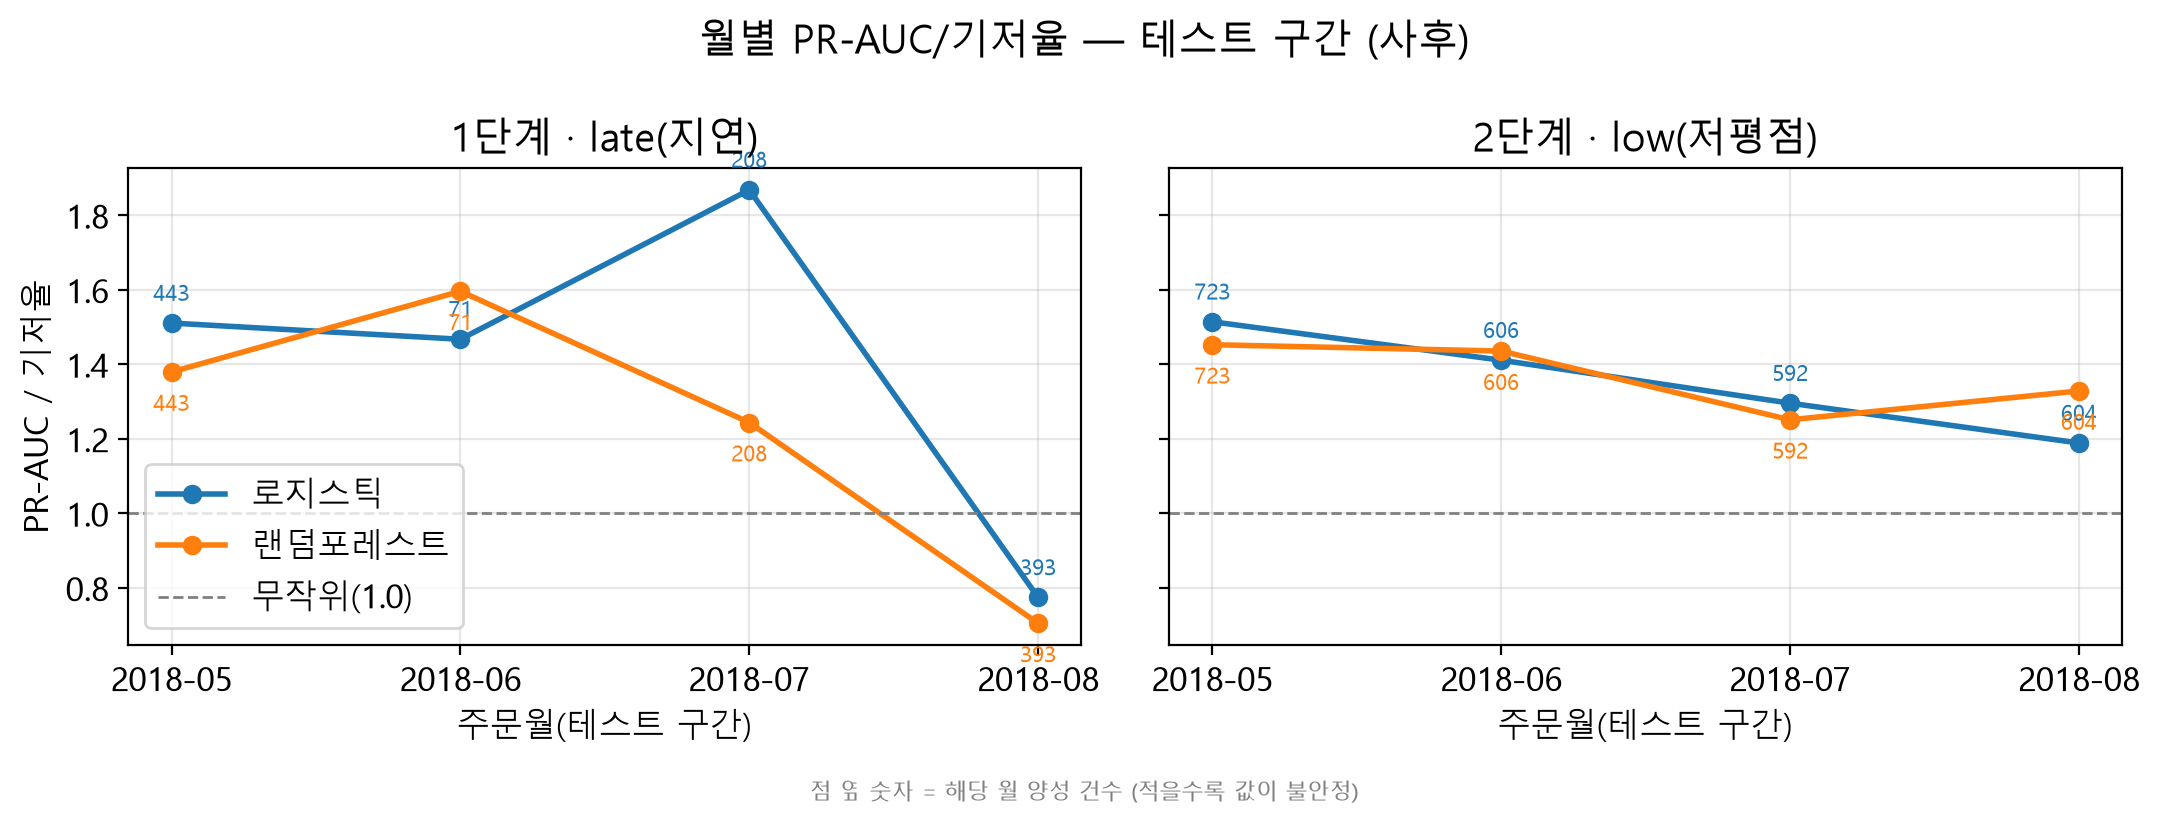

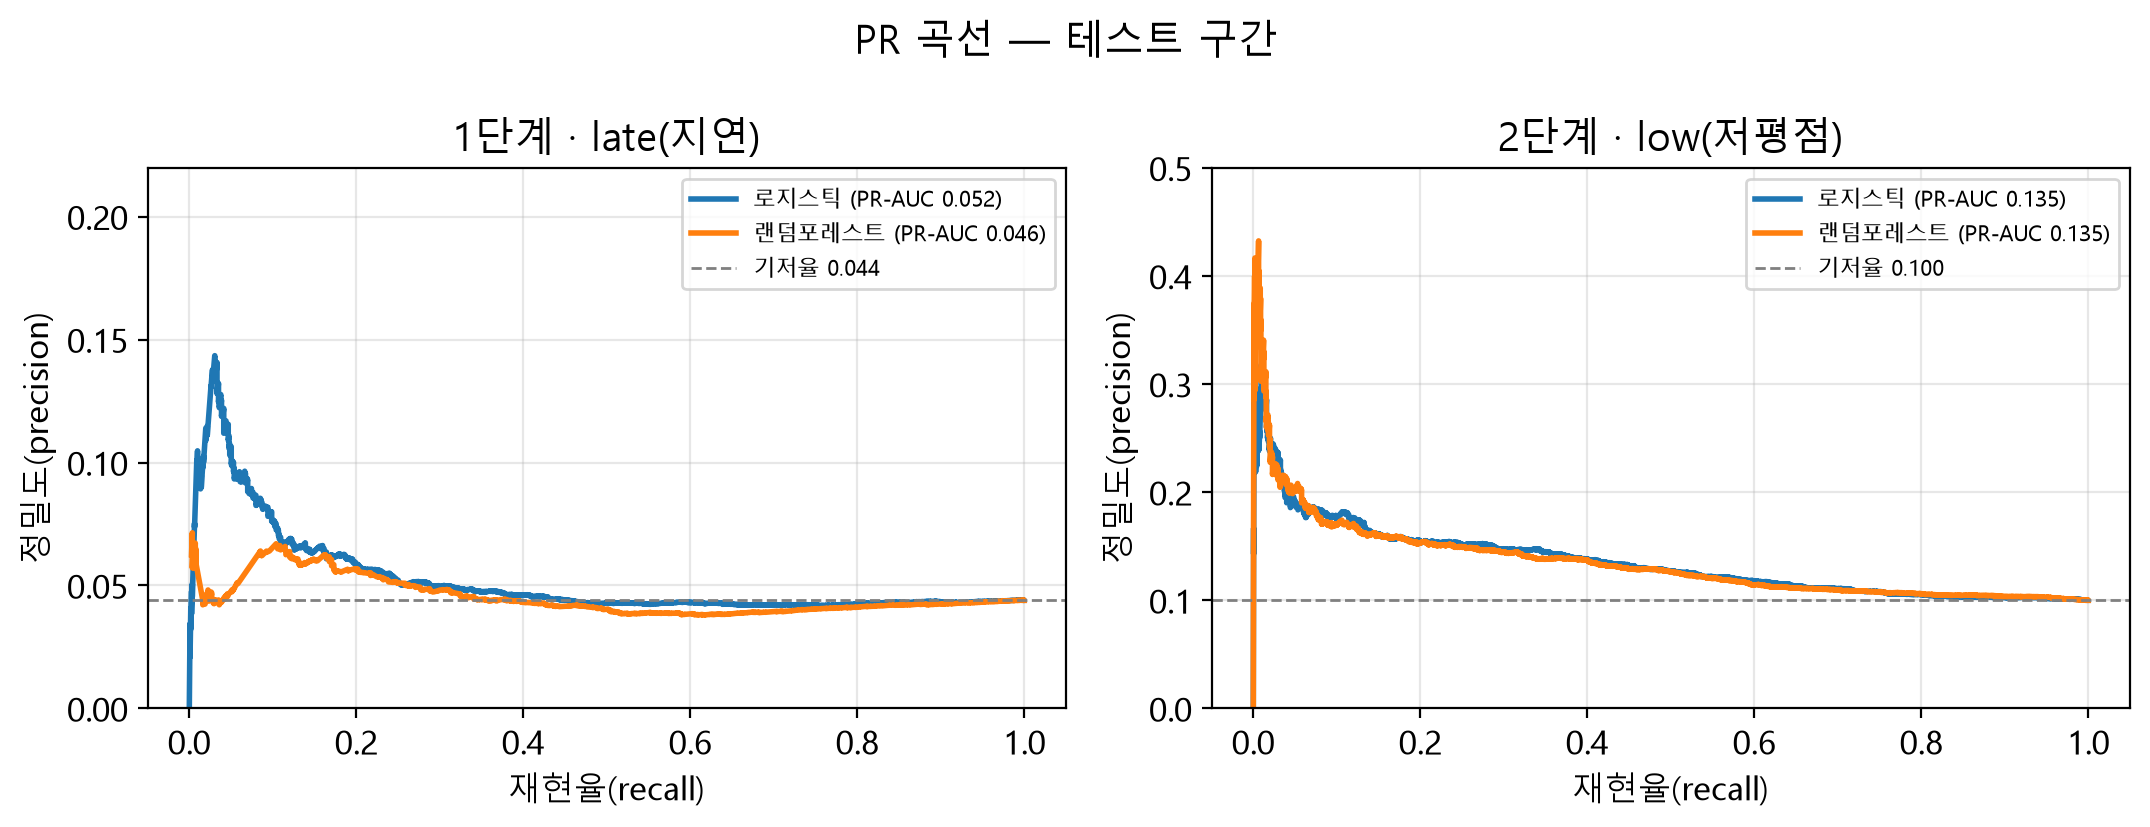

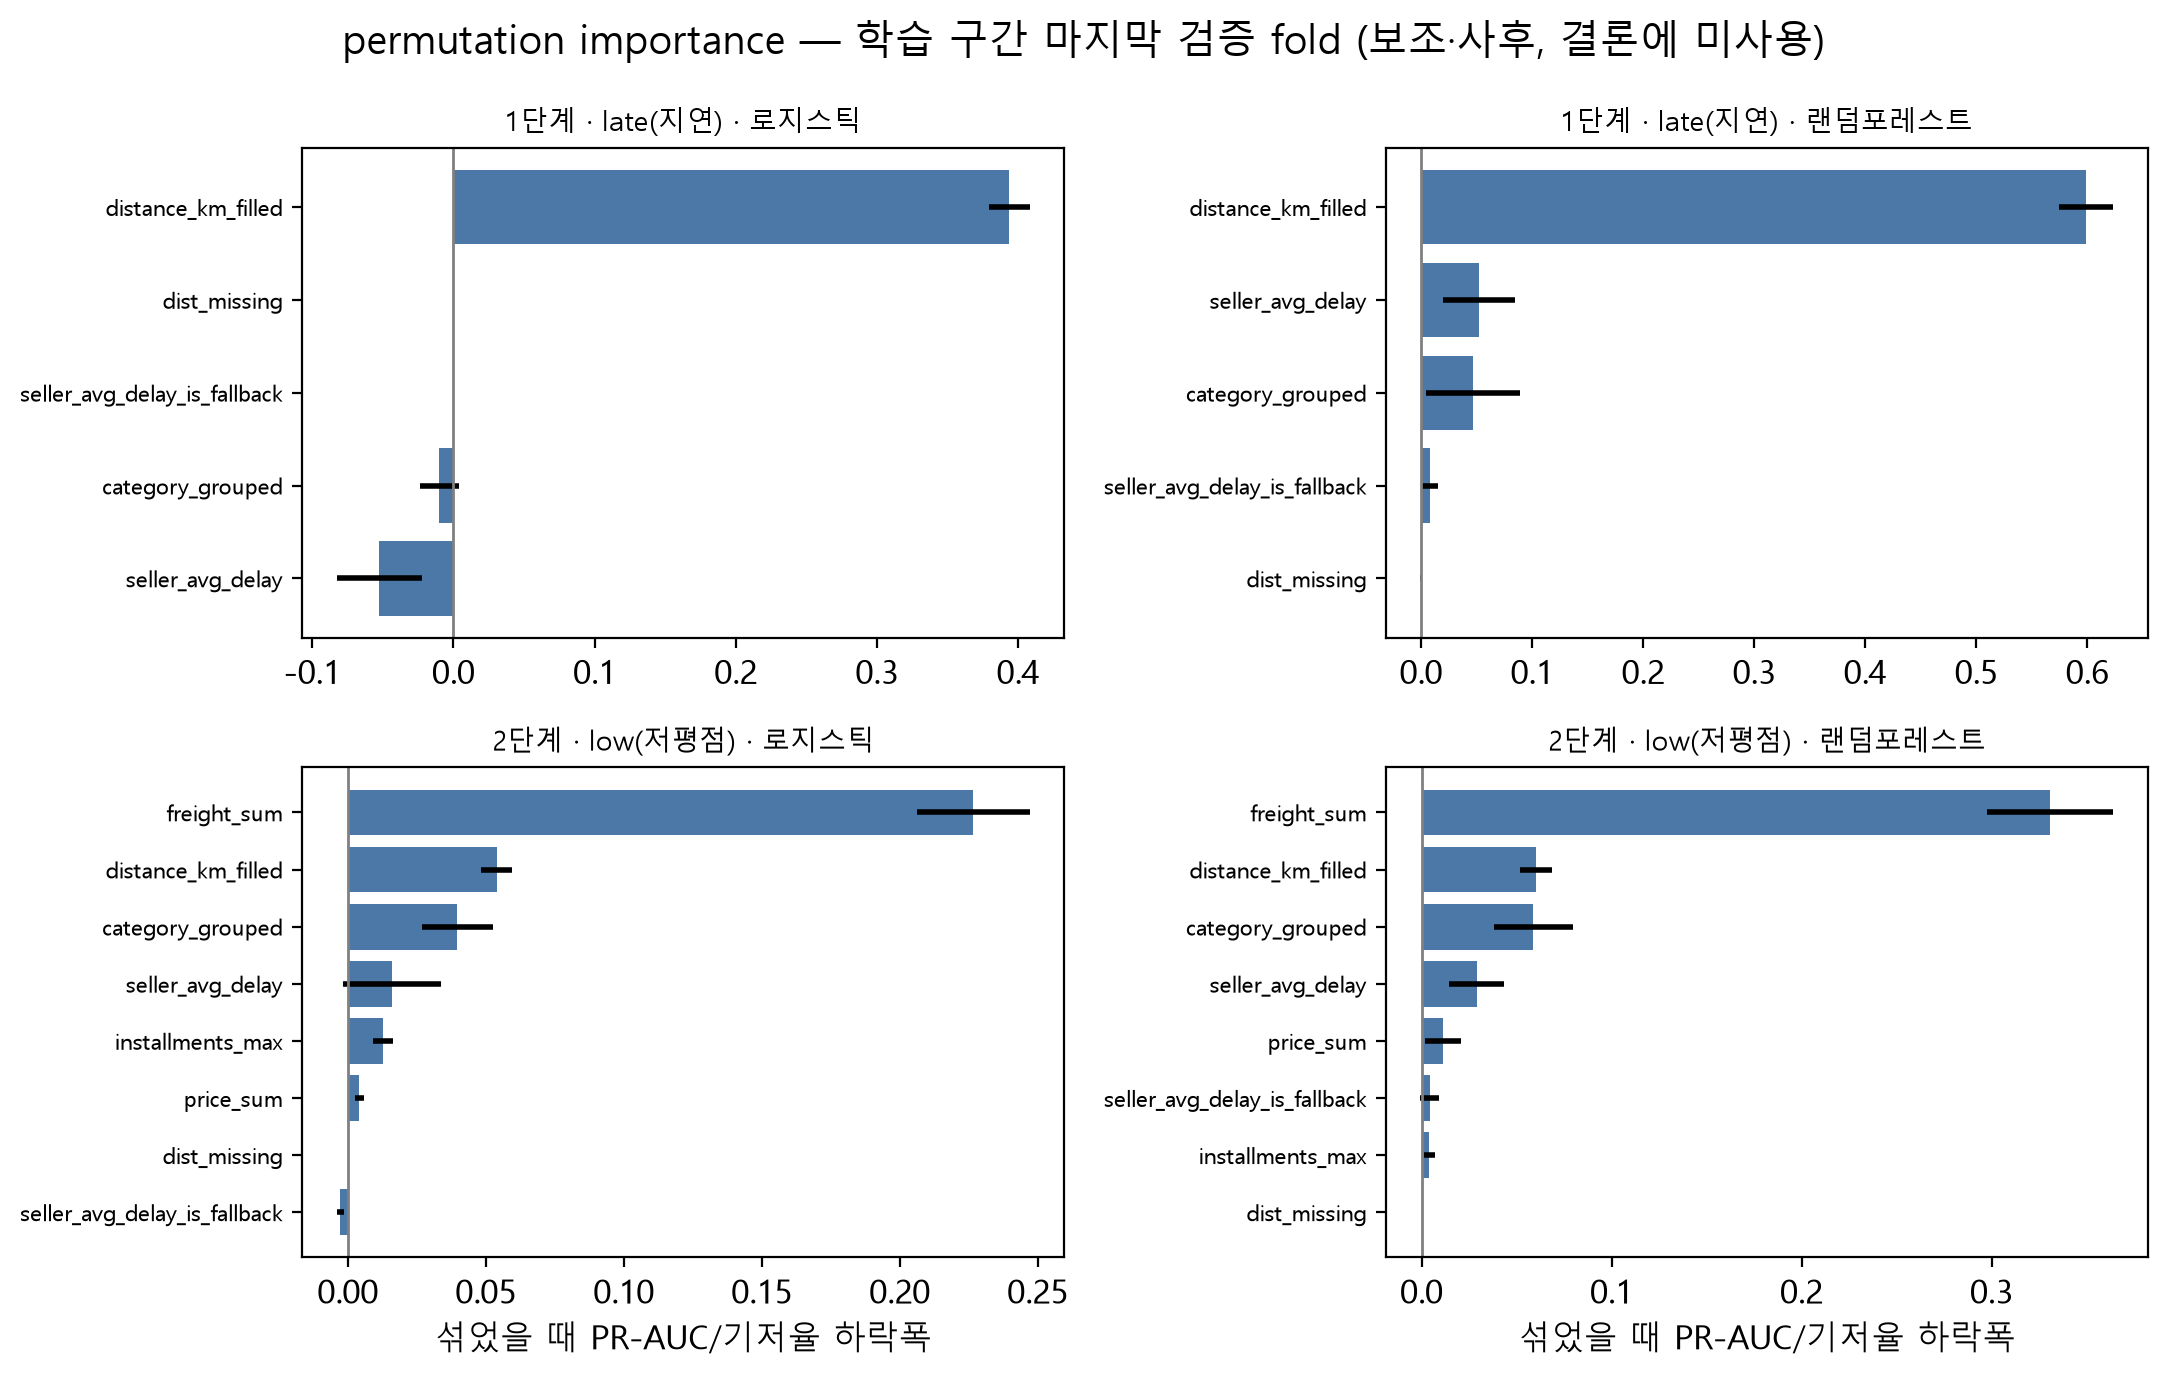

저장: ['08_monthly_ratio.png', '08_perm_importance.png', '08_pr_curves.png']


In [14]:
# 5-2. 그림 3장 (outputs/figures): 월별 추이, PR 곡선, permutation importance
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from matplotlib import font_manager as fm
_avail = {f.name for f in fm.fontManager.ttflist}          # 설치된 폰트만 골라서 findfont 경고가 안 쌓이게 함
plt.rcParams["font.family"] = next((f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if f in _avail), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
STAGE_LABEL = {"stage1": "1단계 · late(지연)", "stage2": "2단계 · low(저평점)"}
MDL_LABEL = {"logit": "로지스틱", "rf": "랜덤포레스트"}

# 그림 1. 월별 PR-AUC/기저율 (테스트 구간) — 1.0 = 무작위 수준
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, stage in zip(axes, ["stage1", "stage2"]):
    for mdl in ["logit", "rf"]:
        d = monthly[(monthly["단계"] == stage) & (monthly["모델"] == mdl)]
        ln, = ax.plot(d["월"], d["PR-AUC/기저율"], marker="o", label=MDL_LABEL[mdl])
        for x_, y_, k_ in zip(d["월"], d["PR-AUC/기저율"], d["양성"]):      # 점마다 그 달 양성 건수 표시
            ax.annotate(f"{int(k_)}", (x_, y_), textcoords="offset points", xytext=(0, 8 if mdl == "logit" else -14),
                        ha="center", fontsize=8, color=ln.get_color())
    ax.axhline(1.0, color="gray", ls="--", lw=1, label="무작위(1.0)")
    ax.set_title(STAGE_LABEL[stage]); ax.set_xlabel("주문월(테스트 구간)"); ax.grid(alpha=.3)
axes[0].set_ylabel("PR-AUC / 기저율"); axes[0].legend()
fig.suptitle("월별 PR-AUC/기저율 — 테스트 구간 (사후)")
fig.text(0.5, 0.005, "점 옆 숫자 = 해당 월 양성 건수 (적을수록 값이 불안정)", ha="center", fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{FIG_DIR}/08_monthly_ratio.png", dpi=150); plt.show()

# 그림 2. PR 곡선 (테스트 구간)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, stage in zip(axes, ["stage1", "stage2"]):
    y = preds[stage]["y"].to_numpy()
    for mdl in ["logit", "rf"]:
        pr, rc, _ = precision_recall_curve(y, preds[stage][f"prob_{mdl}"].to_numpy())
        ax.plot(rc[:-1], pr[:-1], label=f"{MDL_LABEL[mdl]} (PR-AUC {average_precision_score(y, preds[stage][f'prob_{mdl}'].to_numpy()):.3f})")
    ax.axhline(y.mean(), color="gray", ls="--", lw=1, label=f"기저율 {y.mean():.3f}")
    ax.set_title(STAGE_LABEL[stage]); ax.set_xlabel("재현율(recall)"); ax.set_ylabel("정밀도(precision)")
    ax.set_ylim(0, min(1, y.mean() * 5)); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.suptitle("PR 곡선 — 테스트 구간"); fig.tight_layout()
fig.savefig(f"{FIG_DIR}/08_pr_curves.png", dpi=150); plt.show()

# 그림 3. permutation importance (보조·사후, 마지막 검증 fold)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, stage in enumerate(["stage1", "stage2"]):
    for j, mdl in enumerate(["logit", "rf"]):
        ax = axes[i, j]
        d = perm_df[(perm_df["단계"] == stage) & (perm_df["모델"] == mdl)].sort_values("하락(PR-AUC/기저율)")
        ax.barh(d["변수"], d["하락(PR-AUC/기저율)"], xerr=d["표준편차"], color="#4C78A8")
        ax.axvline(0, color="gray", lw=1)
        ax.set_title(f"{STAGE_LABEL[stage]} · {MDL_LABEL[mdl]}", fontsize=10); ax.tick_params(axis="y", labelsize=8)
        if i == 1: ax.set_xlabel("섞었을 때 PR-AUC/기저율 하락폭")
fig.suptitle("permutation importance — 학습 구간 마지막 검증 fold (보조·사후, 결론에 미사용)"); fig.tight_layout()
fig.savefig(f"{FIG_DIR}/08_perm_importance.png", dpi=150); plt.show()
print("저장:", sorted(f for f in os.listdir(FIG_DIR) if f.startswith("08_")))